In [1]:
import numpy as np
import csv
import random
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
import seaborn as sns

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
from google.colab import drive
drive.mount("/content/drive/")

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [3]:
!ls "/content/drive/MyDrive/GSE150910_gene-level_count_file.csv"


/content/drive/MyDrive/GSE150910_gene-level_count_file.csv


Data Preprocessing

In [4]:
genes = []
data = [] # contains expression measurements for each gene

with open("/content/drive/MyDrive/GSE150910_gene-level_count_file.csv") as csvfile:
  reader = csv.reader(csvfile,delimiter = ',')
  for row in reader:
    genes.append(row[0])
    data.append(row[1:])

In [5]:
# the first row in the dataset is a sample row (column headings), so we ignore it
headings = data[0]
data = data[1:]
genes = genes[1:]

In [6]:
data = np.array(data).astype(float)
genes = np.array(genes)
headings = np.array(headings)

In [7]:
# split the headers - eg: chp_26, we will take chp as a label
labels = []
for i in range(len(headings)):
  tmp = headings[i].split("_")
  labels.append(tmp[0])
labels = np.array(labels)

In [8]:
print(np.unique(labels))

['chp' 'control' 'ipf']


We will focus only on control and ipf labels

In [9]:
data = data[:, labels != "chp"]
headings = headings[labels != "chp"]
labels = labels[labels != "chp"]


In [10]:
print(data.shape)
print(genes.shape)
print(headings.shape)

(18838, 206)
(18838,)
(206,)


The data represents the amount of fragments of genetic material that was found in the sample, that came from each gene for each sample. The total number of counts in a sample (in a column) is called the sequencing depth.

For each sample, some genes have higher expression when compared to other genes. The goal is to normalize this, by applying Counts Per Million Normalization (CPM). For each sample, we will divide the counts for each gene by the total number of counts in that sample and then multiply by a million.

In [33]:
for j in range(data.shape[1]):
  column_sum = sum(data[:,j])
  data[:,j] = data [:,j] / column_sum * 1e6

**Review note (fix this first):** the cell above multiplies by `100000`, so the values are counts per 100 thousand, not per million. Change it to `1e6` and rerun. It matters because the filter below (`mean >= 5`) is then really a cutoff of 50 CPM, which throws away many real genes (only 3,183 of 18,838 were kept). The cells added at the end assume this is fixed.

NOTE TO SELF: TRY OTHER NORMALIZATION METHODS

In [34]:
print(data)
print(data.shape)

[[ 87.63810249  99.26815013  68.46937537 ...  72.70170598  79.65638521
   80.95262641]
 [127.49362147 134.13892696 157.36024675 ... 147.77563654  97.17274966
   76.69790698]
 [703.74717479 538.02535742 396.54415054 ...  90.77247551 381.33986864
  466.85191389]
 ...
 [ 31.59816007  55.80214989  41.80670306 ...  70.573681    51.91735561
   58.54945771]
 [ 74.60982511  99.09001078  92.79160657 ... 101.48237174  91.88912497
  108.81539085]
 [ 97.29003757 130.35346587  85.1737002  ... 134.76328705 111.70271755
  111.90288637]]
(3183, 206)


We will apply filters to eliminate genes that have very low expression

In [35]:
mean_CPM_control = data[:,labels == "control"].mean(axis = 1)
mean_CPM_ipf = data [:, labels == "ipf"].mean(axis = 1)
to_keep = (mean_CPM_control >= 5) | (mean_CPM_ipf >= 5)
data = data[to_keep,:] # only the rows in to keep with high gene expression
genes = genes[to_keep]

In [36]:
print(data)
print(data.shape)

[[ 87.63810249  99.26815013  68.46937537 ...  72.70170598  79.65638521
   80.95262641]
 [127.49362147 134.13892696 157.36024675 ... 147.77563654  97.17274966
   76.69790698]
 [703.74717479 538.02535742 396.54415054 ...  90.77247551 381.33986864
  466.85191389]
 ...
 [ 31.59816007  55.80214989  41.80670306 ...  70.573681    51.91735561
   58.54945771]
 [ 74.60982511  99.09001078  92.79160657 ... 101.48237174  91.88912497
  108.81539085]
 [ 97.29003757 130.35346587  85.1737002  ... 134.76328705 111.70271755
  111.90288637]]
(3183, 206)


NOTE TO SELF: add steps like batch correction, based on demographic info about subjects (sex, race, age, health status etc.) identifying outliers and thinking about if one should remove them or not

Differential Expression Analysis:

Kolmogorov Smirnov test (the K-S test): Whether two observed distributions are drawn from the same underlying distribution or from a different underlying distribution.

The null hypothesis: Two observed distribution came from the same underlying distribution.

Alternative hypothesis is that they came from different underlying distribution.

Find more advanced statistical methods to test this.

In [37]:
control = data[0, labels == "control"] # we consider the first gene
ipf = data[0, labels == "ipf"]
print(control.shape)
print(ipf.shape)

(103,)
(103,)


We perform the ks test which will give us the p-value for this experiment.

In [38]:
ks_statistic, p_value = ks_2samp(control,ipf)
print(f"ks_statistic: {ks_statistic}")
print(f"p_value: {p_value}")

ks_statistic: 0.21359223300970873
p_value: 0.017970743626588136


we use log, to create a symmetry around 0. So that the absolute value of a change in either direction would be the same. but it would be positive or negative depending on which is greater

log 2 = mean(ipf) / mean(control)

the problem with the above equation is that if one of the mean values is 0 then the result will be undefined / 0. So, the little hack is we add epsilon to both NR and DR. Epsilon can be any small value (0.1,0.01 or 1).

Again, this is just a test of whether the distriubtions are different, and doesn't tell us whether or not there's a difference in means (which is what we're really interested in). So besides getting the p-value for the statistical test, we also want to calculate something called the
(fold change) between the mean expression level in each condition:



The inside fraction

 is the fold change. This tells us how different the mean expression of the IPF samples is compared to the control samples. The reason we're using
 is to make this measurement symetrical around 0. So if a gene's mean expression in IPF samples is twice the mean of the control samples, then

. If it's half the mean of the control samples, then

.

One more thing before we actualy calculate this -- if either of the means is 0, that will cause a problem for us. We can't divide by 0, and we also can't do
. We'll deal with this by defining a small constant called epsilon (often 1, 0.1, or 0.01) and adding it to both means before doing the calculation.

In [39]:
# we calculate this for the first gene
epsilon = 1
control_mean = np.mean(control)
ipf_mean = np.mean(ipf)
# fc stands for fold chagne
FC = (ipf_mean + epsilon) / (control_mean + epsilon)
log2_fc = np.log2(FC)

print(log2_fc)


0.11058444330471322


In [40]:
# we calculate p-value and log2fc for every gene
p_values = []
log2_fcs= []
epsilon = 1
for i in range(data.shape[0]):
  control = data[i, labels == "control"]
  ipf = data[i, labels == 'ipf']
  ks_statistic,p_value = ks_2samp(control,ipf)
  p_values.append(p_value)
  control_mean = np.mean(control)
  ipf_mean = np.mean(ipf)
  FC = (ipf_mean + epsilon) / (control_mean + epsilon)
  log2_fc = np.log2(FC)
  log2_fcs.append(log2_fc)
# cast pvalues and log2fcs as numpy arrays
p_values = np.array(p_values)
log2_fcs = np.array(log2_fcs)

In [41]:
print(p_values)
print(log2_fcs)

[1.79707436e-02 5.73482939e-07 1.05136921e-33 ... 1.60855670e-03
 4.47488945e-05 2.25433246e-01]
[ 0.11058444 -0.6531461   1.29055389 ... -0.1992791   0.09107433
 -0.04948655]


The threshold 0.05 means that we see a coincidence only 5% of the time when we run the experiment. But here we did not run a single test, we ran around 11k experiments which is why we cannot use the same 0.05 as threshold. The more tests we do, the more likely for it to be a coincidence.
P - value is the probability of observing a results as extreme as the one we got, if null hypothesis is true. (random chance)

So we either have to adjust the p-values or the cut-offs



Bonferroni correction: multiplying each p-value by the number of tests we did.

NOTE TO SELF: use Benjamini Hochberg correction

In [42]:
p_values_bonf = p_values * len(genes)

# Improvements
Everything below reuses the variables from above (`data`, `genes`, `labels`, `headings`, `p_values`, `log2_fcs`), so run the notebook top to bottom first.

In [43]:
!pip install -q pydeseq2 gseapy
import pandas as pd
from scipy.stats import ttest_ind, mannwhitneyu, spearmanr, false_discovery_control
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score, ConfusionMatrixDisplay
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import gseapy as gp

## 1. Multiple testing: Bonferroni fix + Benjamini-Hochberg
Bonferroni can push p-values above 1, which isn't a valid probability, so we cap them at 1. Benjamini-Hochberg (BH) controls the false discovery rate: the expected share of false hits among the genes you call significant. It's the standard in gene expression work and less harsh than Bonferroni, which is built to avoid even a single false hit.

In [44]:
p_values_bonf = np.minimum(p_values * len(genes), 1)
p_values_bh = false_discovery_control(p_values)   # BH by default

print("KS hits, raw p < 0.05:       ", (p_values < 0.05).sum())
print("KS hits, Bonferroni < 0.05:  ", (p_values_bonf < 0.05).sum())
print("KS hits, BH FDR < 0.05:      ", (p_values_bh < 0.05).sum())

KS hits, raw p < 0.05:        1979
KS hits, Bonferroni < 0.05:   916
KS hits, BH FDR < 0.05:       1880


## 2. Log transform + sample QC with PCA
CPM values are very skewed (a few genes are huge), so we use log2(CPM + 1). It makes the values closer to normal, which t-tests and most ML models assume.

PCA squeezes 3,000+ genes into 2 axes. If IPF and control separate on their own, there's a strong disease signal. It also shows outlier samples (your note about outliers): samples far from their group are worth checking before trusting results.

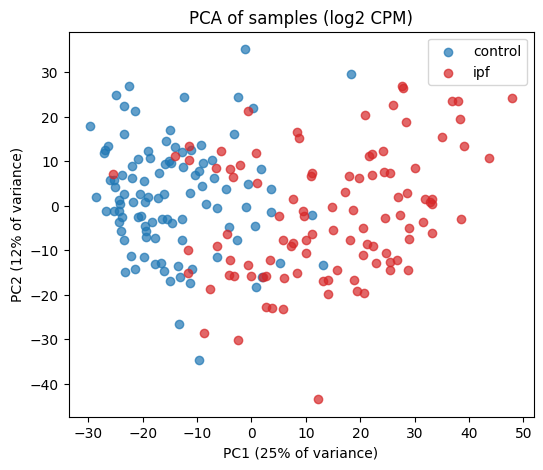

control possible outliers: ['control_750' 'control_912' 'control_657' 'control_687']
ipf possible outliers: []


In [45]:
logcpm = np.log2(data + 1)          # genes x samples
X = logcpm.T                        # samples x genes (sklearn format)
y = (labels == "ipf").astype(int)

pca = PCA(n_components=2).fit(X)
Z = pca.transform(X)
plt.figure(figsize=(6, 5))
for lab, c in [("control", "tab:blue"), ("ipf", "tab:red")]:
    plt.scatter(Z[labels == lab, 0], Z[labels == lab, 1], c=c, label=lab, alpha=0.7)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
plt.title("PCA of samples (log2 CPM)"); plt.legend(); plt.show()

# samples more than 3 SDs from their group's center on PC1/PC2
for lab in ["control", "ipf"]:
    z = Z[labels == lab]
    dist = np.linalg.norm((z - z.mean(0)) / z.std(0), axis=1)
    print(lab, "possible outliers:", headings[labels == lab][dist > 3])

## 3. Tests that compare means
KS asks "are the two distributions different in any way?" (shape, spread, anything). What we actually care about is whether the average expression changed. Welch's t-test compares means without assuming equal variances. Mann-Whitney is a rank-based version that is robust to a few extreme samples. Both run on log2 CPM with BH correction, and we compare hit counts with KS.

In [46]:
p_t = ttest_ind(logcpm[:, y == 1], logcpm[:, y == 0], axis=1, equal_var=False).pvalue
p_mw = mannwhitneyu(logcpm[:, y == 1], logcpm[:, y == 0], axis=1).pvalue

print("Genes significant at BH FDR < 0.05:")
print(pd.Series({
    "KS": (p_values_bh < 0.05).sum(),
    "Welch t-test": (false_discovery_control(p_t) < 0.05).sum(),
    "Mann-Whitney": (false_discovery_control(p_mw) < 0.05).sum(),
}))

Genes significant at BH FDR < 0.05:
KS              1880
Welch t-test    1876
Mann-Whitney    1896
dtype: int64


## 4. DESeq2: the standard model for RNA-seq counts
This is the biggest upgrade. RNA-seq counts aren't normally distributed: they are whole numbers, and their variance grows with the mean. DESeq2 models them with a negative binomial distribution, normalizes for sequencing depth on its own (more robust than CPM), and stabilizes noisy variance estimates by borrowing information across genes. This is the method a professor would expect to see.

It needs **raw counts**, so we reload the file and keep the same samples and genes as above. We also plot sequencing depth per group, because a big depth difference between groups can bias results.

/tmp/ipykernel_1812/2646585585.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  sns.boxplot(x=labels, y=raw[headings].sum(0).values / 1e6)


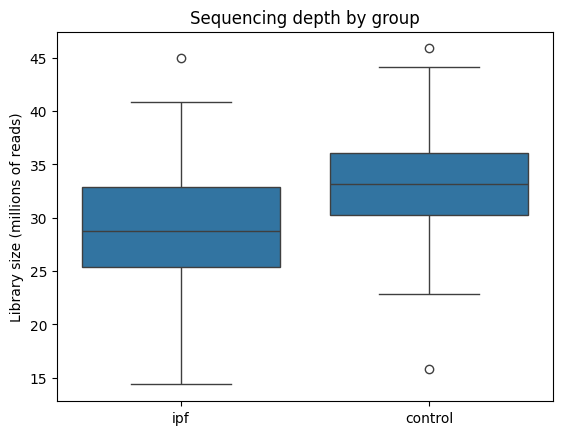

Log2 fold change & Wald test p-value: condition ipf vs control
               baseMean  log2FoldChange     lfcSE       stat        pvalue  \
symbol                                                                       
DPM1        2078.008637        0.114629  0.037271   3.075549  2.101152e-03   
FGR         3385.181233       -0.664627  0.096599  -6.880254  5.974591e-12   
CFH         5898.785140        1.292358  0.076315  16.934491  2.505178e-64   
FUCA2       1769.312105        0.091461  0.038187   2.395062  1.661757e-02   
BAD         3718.610410       -0.037470  0.041817  -0.896034  3.702344e-01   
...                 ...             ...       ...        ...           ...   
CCL14       2032.596674        0.899196  0.165453   5.434753  5.487237e-08   
AC007906.2  1582.641355        1.944599  0.227823   8.535572  1.394639e-17   
CISD3       1605.199615       -0.185992  0.047811  -3.890191  1.001652e-04   
C11orf98    2859.379698        0.105765  0.048149   2.196620  2.804763e-02   
G

In [47]:
raw = pd.read_csv("/content/drive/MyDrive/GSE150910_gene-level_count_file.csv", index_col=0)
counts = raw.loc[genes, headings].T.round().astype(int)   # samples x genes
meta = pd.DataFrame({"condition": labels}, index=headings)

sns.boxplot(x=labels, y=raw[headings].sum(0).values / 1e6)
plt.ylabel("Library size (millions of reads)"); plt.title("Sequencing depth by group"); plt.show()

dds = DeseqDataSet(counts=counts, metadata=meta, design="~condition")
dds.deseq2()
stats = DeseqStats(dds, contrast=["condition", "ipf", "control"])   # log2FC = IPF / control
stats.summary()
res = stats.results_df.dropna()

sig = (res.padj < 0.05) & (res.log2FoldChange.abs() > 1)   # FDR < 5% and at least 2x change
print(f"DESeq2 hits: {sig.sum()} ({(sig & (res.log2FoldChange > 0)).sum()} up, "
      f"{(sig & (res.log2FoldChange < 0)).sum()} down in IPF)")

## 5. Volcano and MA plots
**Volcano plot:** x is effect size (log2FC), y is confidence (-log10 adjusted p). Genes in the top corners changed a lot *and* reliably. Red = up in IPF, blue = down, grey = not significant. The 10 strongest hits are labeled.

**MA plot:** x is average expression, y is log2FC. It checks for a common artifact: low-count genes producing huge, unreliable fold changes.

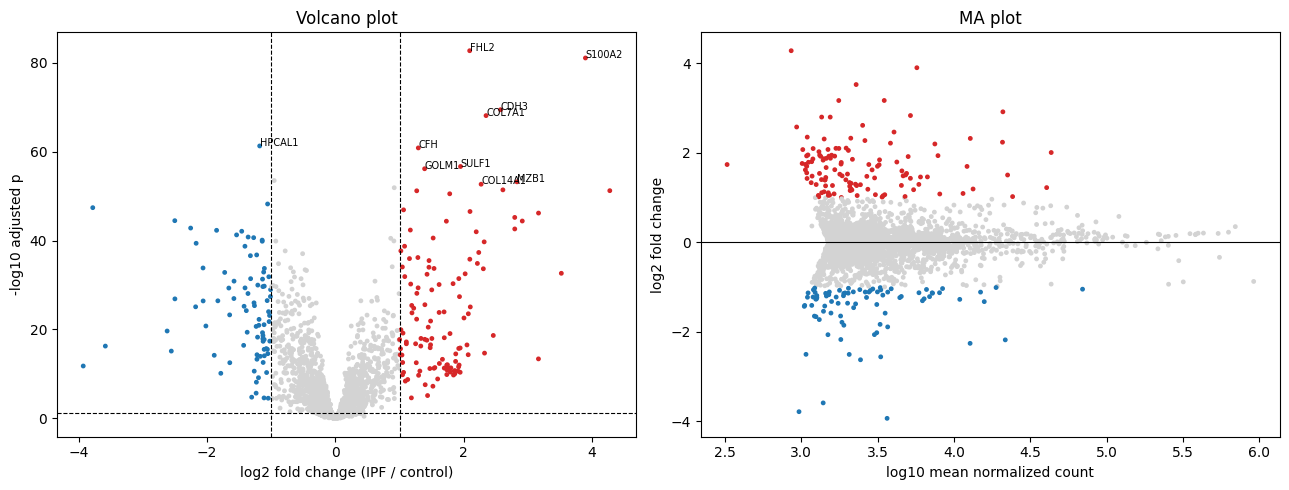

In [48]:
colors = np.where(~sig, "lightgrey", np.where(res.log2FoldChange > 0, "tab:red", "tab:blue"))
neglogp = -np.log10(res.padj + 1e-300)   # avoid log(0)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(res.log2FoldChange, neglogp, c=colors, s=6)
ax[0].axhline(-np.log10(0.05), ls="--", c="k", lw=0.8)
for x in (-1, 1):
    ax[0].axvline(x, ls="--", c="k", lw=0.8)
for g in res[sig].nsmallest(10, "padj").index:
    ax[0].annotate(g, (res.log2FoldChange[g], neglogp[g]), fontsize=7)
ax[0].set(xlabel="log2 fold change (IPF / control)", ylabel="-log10 adjusted p", title="Volcano plot")

ax[1].scatter(np.log10(res.baseMean), res.log2FoldChange, c=colors, s=6)
ax[1].axhline(0, c="k", lw=0.8)
ax[1].set(xlabel="log10 mean normalized count", ylabel="log2 fold change", title="MA plot")
plt.tight_layout(); plt.show()

## 6. Do the methods agree?
If your original KS + fold-change results broadly agree with DESeq2, that's evidence the findings are real and not a quirk of one test. Spearman correlation compares the fold-change rankings; the overlap compares the significant gene sets.

In [49]:
idx = pd.Index(genes).get_indexer(res.index)
print("Spearman, your log2FC vs DESeq2 log2FC:", round(spearmanr(log2_fcs[idx], res.log2FoldChange).statistic, 3))

ks_set, de_set = set(genes[p_values_bh < 0.05]), set(res.index[res.padj < 0.05])
print(f"KS (BH) hits: {len(ks_set)}, DESeq2 hits: {len(de_set)}, overlap: {len(ks_set & de_set)}")

Spearman, your log2FC vs DESeq2 log2FC: 0.999
KS (BH) hits: 1880, DESeq2 hits: 1960, overlap: 1720


## 7. Heatmap and boxplots of the top genes
The heatmap shows the top 50 DESeq2 genes across all samples. Each gene is z-scored, so color means above or below that gene's own average. The color bar on top marks control (blue) vs IPF (red). If the clustering groups samples by disease without being told the labels, the signature is strong.

Boxplots of the top 6 show the actual spread, which catches a "significant" result driven by a handful of extreme samples.

/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


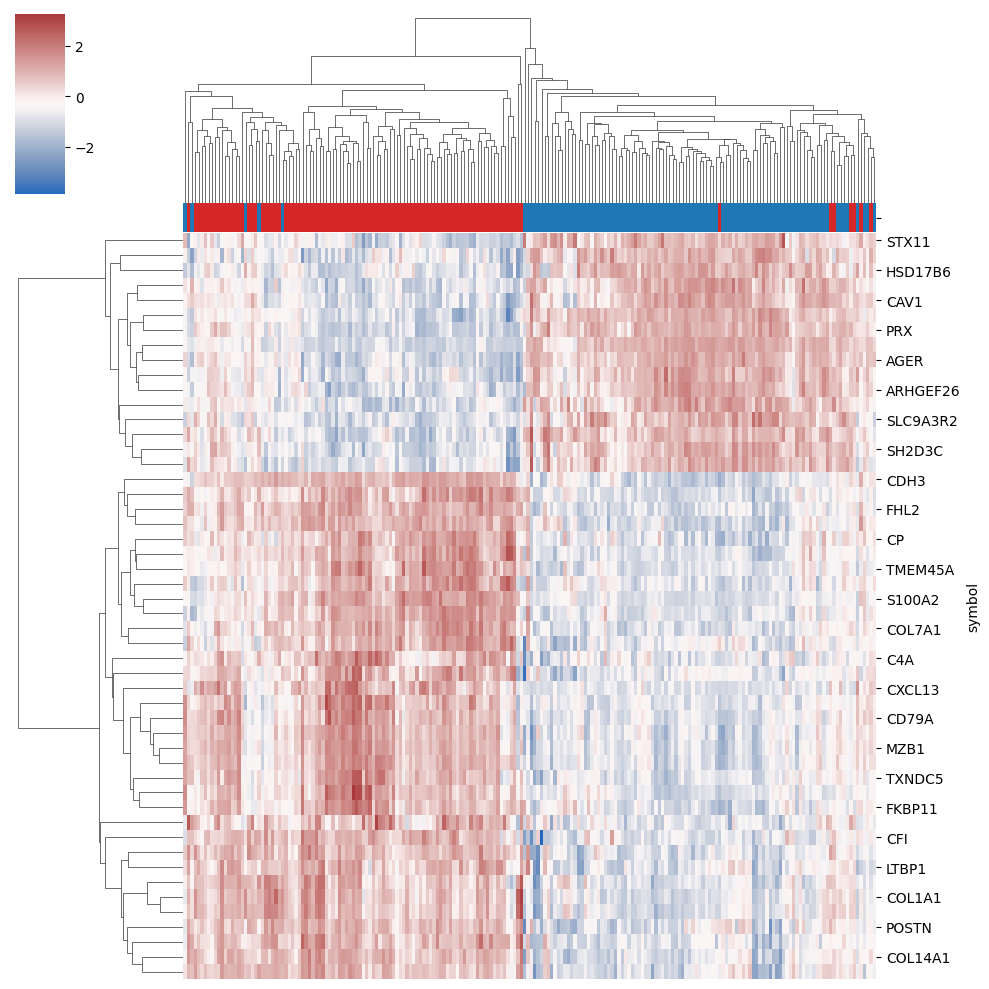

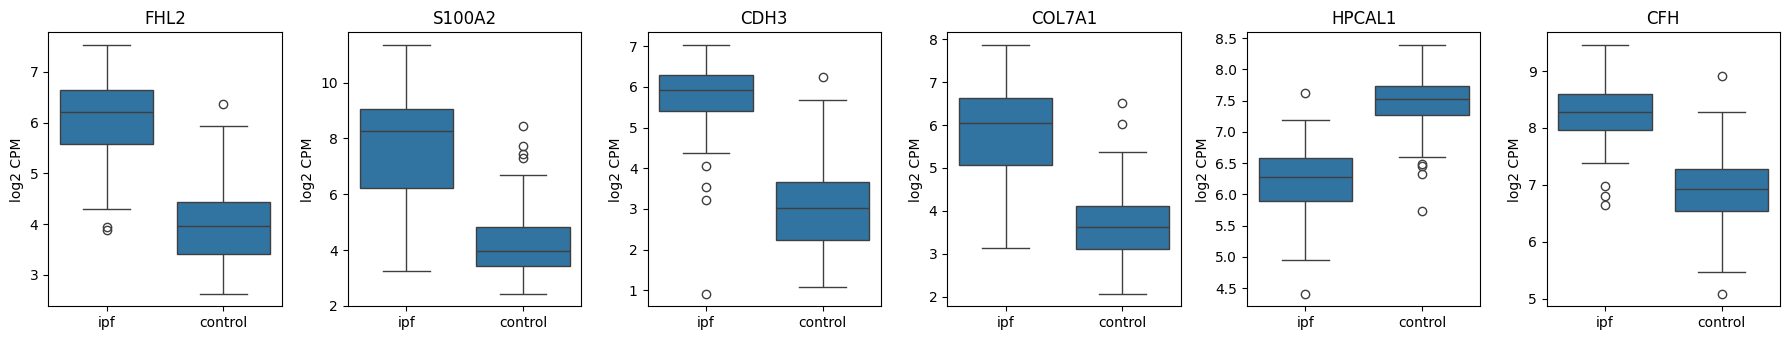

In [50]:
top50 = res[sig].nsmallest(50, "padj").index
hm = pd.DataFrame(logcpm[pd.Index(genes).get_indexer(top50)], index=top50, columns=headings)
col_colors = pd.Series(labels, index=headings).map({"control": "tab:blue", "ipf": "tab:red"})
sns.clustermap(hm, z_score=0, cmap="vlag", col_colors=col_colors, xticklabels=False, figsize=(10, 10))
plt.show()

fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
for a, g in zip(axes, top50[:6]):
    sns.boxplot(x=labels, y=logcpm[genes == g][0], ax=a)
    a.set_title(g); a.set_ylabel("log2 CPM")
plt.tight_layout(); plt.show()

## 8. Sanity check against known IPF genes
Genes already known to be raised in IPF lungs (MMP7, SPP1, collagens, MUC5B, ...) should come out as up-regulated with small adjusted p-values. If they do, the pipeline is working. If the table is empty, your file probably uses Ensembl IDs instead of gene symbols.

In [51]:
known = ["MMP7", "MMP1", "SPP1", "COL1A1", "COL3A1", "COMP", "CXCL14", "MUC5B"]
print(res.loc[res.index.intersection(known), ["log2FoldChange", "padj"]])

        log2FoldChange          padj
symbol                              
COL1A1        2.319057  1.879601e-40
MUC5B         3.521831  2.232809e-33
SPP1          2.324596  2.078261e-15
CXCL14        2.072043  2.867393e-24
COL3A1        2.234500  4.592888e-38


## 9. ML classifier: can expression predict IPF vs control?
The important detail here is **data leakage**. If you pick the top genes using all samples and then cross-validate a classifier on them, the test samples already influenced which genes were chosen, so the score is inflated. Putting gene selection (`SelectKBest`) *inside* the pipeline means it's redone on the training folds only.

Two models: L1 logistic regression (keeps only a small set of genes, so it's easy to interpret) and random forest (can capture non-linear effects). We use 5-fold stratified cross-validation and report several metrics, because accuracy alone can hide problems. ROC-AUC measures how well the model ranks IPF above control across all thresholds; balanced accuracy and F1 matter when classes are uneven. `k=200` genes and `C=0.1` are starting values you can tune.

Expect very high scores: IPF vs control is an easy split. The value here is showing the evaluation is done correctly.

L1 logistic regression {'roc_auc': '0.985 ± 0.026', 'accuracy': '0.951 ± 0.044', 'balanced_accuracy': '0.951 ± 0.044', 'f1': '0.952 ± 0.040'}
Random forest {'roc_auc': '0.980 ± 0.033', 'accuracy': '0.932 ± 0.052', 'balanced_accuracy': '0.931 ± 0.053', 'f1': '0.932 ± 0.050'}


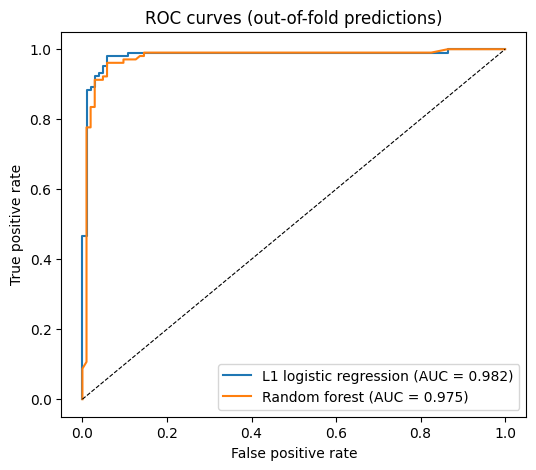

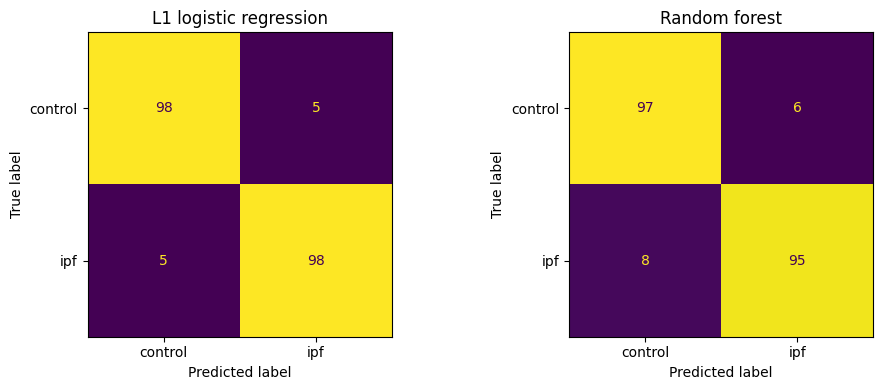

In [52]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
models = {
    "L1 logistic regression": make_pipeline(StandardScaler(), SelectKBest(f_classif, k=200),
                                            LogisticRegression(penalty="l1", solver="liblinear", C=0.1)),
    "Random forest": make_pipeline(SelectKBest(f_classif, k=200),
                                   RandomForestClassifier(n_estimators=500, random_state=0)),
}
metrics = ["roc_auc", "accuracy", "balanced_accuracy", "f1"]

probs = {}
plt.figure(figsize=(6, 5))
for name, model in models.items():
    s = cross_validate(model, X, y, cv=cv, scoring=metrics)
    print(name, {m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std():.3f}" for m in metrics})
    probs[name] = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y, probs[name]):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves (out-of-fold predictions)"); plt.legend(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, p) in zip(ax, probs.items()):
    ConfusionMatrixDisplay.from_predictions(y, (p > 0.5).astype(int), display_labels=["control", "ipf"],
                                            ax=a, colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.show()

## 10. Which genes does the classifier use?
We refit the L1 model on all samples only to read its weights (not to score it; scoring was done above). The genes with nonzero weights form a small "gene panel." Checking overlap with the DESeq2 hits connects the ML result to the statistics result.

12 genes in the panel, 9 of them are also DESeq2 hits


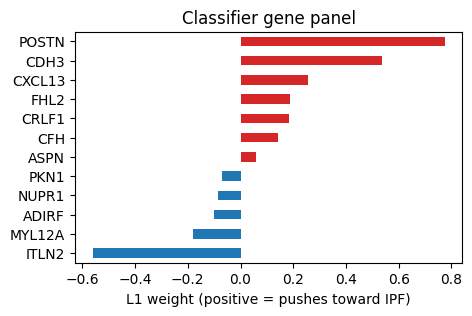

In [53]:
lr = models["L1 logistic regression"].fit(X, y)
kept = genes[lr.named_steps["selectkbest"].get_support()]
coef = lr.named_steps["logisticregression"].coef_[0]
panel = pd.Series(coef, index=kept)[coef != 0].sort_values()
print(f"{len(panel)} genes in the panel, {panel.index.isin(res.index[sig]).sum()} of them are also DESeq2 hits")

panel.plot.barh(figsize=(5, max(3, len(panel) * 0.2)), color=np.where(panel > 0, "tab:red", "tab:blue"))
plt.xlabel("L1 weight (positive = pushes toward IPF)"); plt.title("Classifier gene panel"); plt.show()

## 11. Pathway enrichment
A gene list alone is hard to interpret. Enrichment asks: are the up- (or down-) regulated genes over-represented in known biological processes? For IPF you'd expect things like extracellular matrix organization and collagen-related pathways. This calls the Enrichr web service, so it needs internet (Colab has it) and gene symbols.

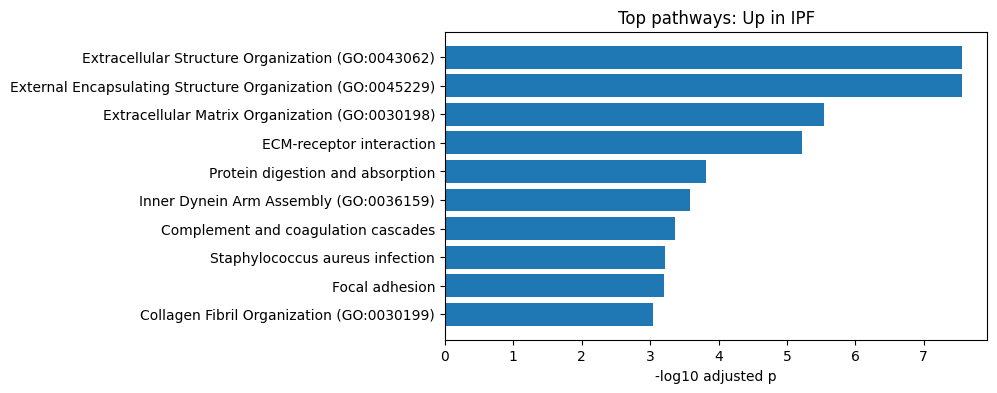

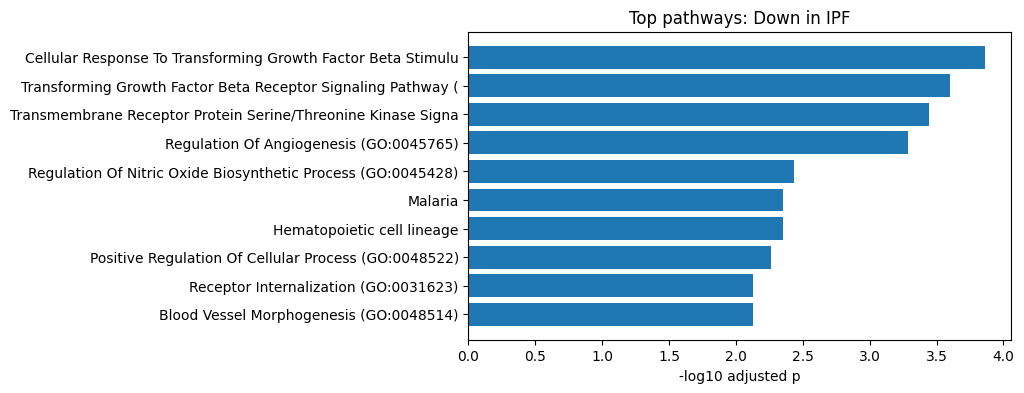

In [54]:
for name, direction in [("Up in IPF", 1), ("Down in IPF", -1)]:
    gene_list = res[sig & (np.sign(res.log2FoldChange) == direction)].index.tolist()
    enr = gp.enrichr(gene_list=gene_list, gene_sets=["GO_Biological_Process_2023", "KEGG_2021_Human"],
                     organism="human", outdir=None).results
    top = enr.nsmallest(10, "Adjusted P-value")
    plt.figure(figsize=(7, 4))
    plt.barh(top.Term.str[:60], -np.log10(top["Adjusted P-value"]))
    plt.gca().invert_yaxis()
    plt.xlabel("-log10 adjusted p"); plt.title(f"Top pathways: {name}"); plt.show()